In [1]:
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
import os 
os.chdir("E:/Machine_Learning/Datasets")

In [2]:
milk = pd.read_csv('milk.csv',index_col=0)
milk.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [3]:
scaler = StandardScaler().set_output(transform='pandas')
scl_milk = scaler.fit_transform(milk)

In [4]:
km = KMeans(n_clusters=5,random_state=26)
km.fit(scl_milk)
km.inertia_

13.355155838326493

In [8]:
wss_scores = []
for k in range(1,21):
    km = KMeans(n_clusters=k,random_state=26)
    km.fit(scl_milk)
    wss_scores.append([k,km.inertia_])

df_wss = pd.DataFrame(wss_scores,columns=["K","score"])
df_wss

,K,score
0,1,125.000000
1,2,49.854660
2,3,36.837336
3,4,18.493970
4,5,13.355156
5,6,10.668394
6,7,8.988012
7,8,6.338370
8,9,4.883256
9,10,3.976010


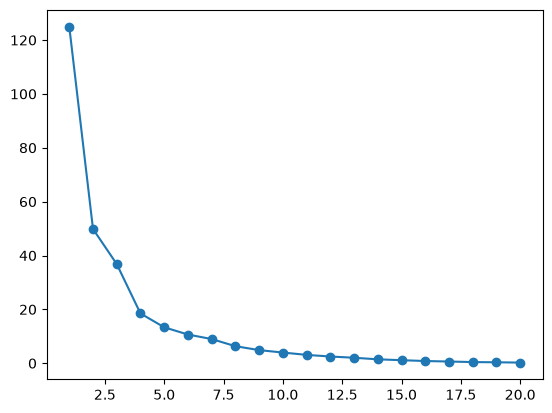

In [9]:
plt.scatter(df_wss['K'],df_wss['score'])
plt.plot(df_wss['K'],df_wss['score'])
plt.show()

### x-axis creates range of k and plot the graph so , To get all values of K on x-axis we convert it into string

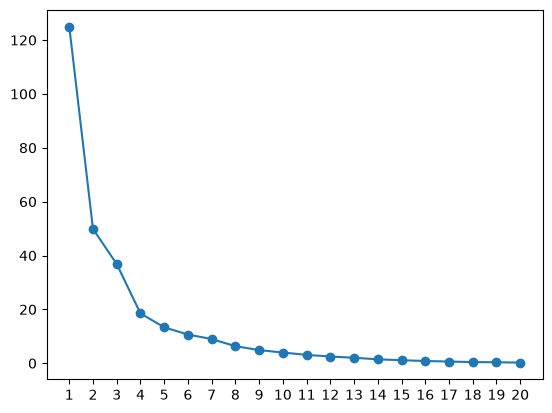

In [10]:
df_wss['K'] = df_wss['K'].astype(str)
plt.scatter(df_wss['K'],df_wss['score'])
plt.plot(df_wss['K'],df_wss['score'])
plt.show()

### BY Elbow method we can say 4 is number of optimal clusters

### Nutrients

In [15]:
neu = pd.read_csv('nutrient.csv',index_col=0)
neu.shape

(27, 5)

In [14]:
scaler = StandardScaler()
neu_sca= scaler.fit_transform(neu)

In [28]:
scores = []
for k in range(1,20):
    km = KMeans(n_clusters=k)
    km.fit(neu_sca)
    scores.append([k,km.inertia_])
df_scores = pd.DataFrame(scores,columns=['K','scores'])
df_scores

,K,scores
0,1,135.000000
1,2,95.887203
2,3,64.488062
3,4,44.892239
4,5,30.406662
5,6,23.692591
6,7,21.732919
7,8,14.453528
8,9,10.676615
9,10,9.224417


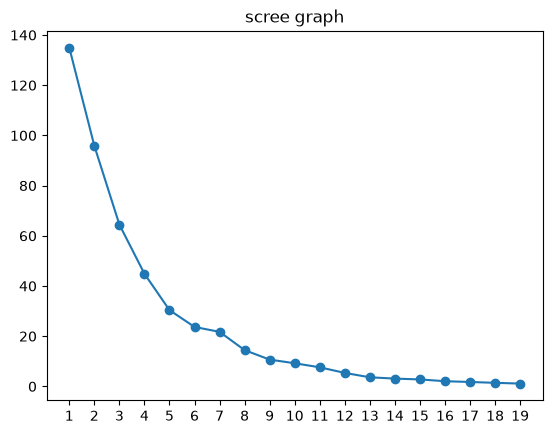

In [29]:
df_scores['K']= df_scores['K'].astype(str)
plt.scatter(df_scores['K'],df_scores['scores'])
plt.plot(df_scores['K'],df_scores['scores'])
plt.title('scree graph')
plt.show()

#### BY Elbow method we can say 6 is number of optimal clusters

## Best Cluster Based on silhoutte score

In [34]:
scores = []
for k in range(2,20):
    km = KMeans(n_clusters=k)
    km.fit(neu_sca)
    scores.append([k,silhouette_score(neu_sca,km.labels_)])
df_scores = pd.DataFrame(scores,columns=['K','scores'])
df_scores.sort_values(by = 'scores',ascending=False)
df_scores.nlargest(1,columns='scores')

,K,scores
11,13,0.439462
